# Bài 1: LeNet-5 trên VinaFood21

So sánh LeNet-5 sử dụng AvgPool và MaxPool; optimizer Adam.

In [ ]:
from pathlib import Path
import os
import sys
import json

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

CODE_BASE = Path("*path chứa source code*")
CODE_CANDIDATES = [
    CODE_BASE / str(EXERCISE),
    CODE_BASE / str(EXERCISE) / str(EXERCISE),
]
CODE_DIR = next(
    (path for path in CODE_CANDIDATES if (path / "train.py").is_file()),
    None,
)

DATA_BASE = Path("*path chứa dữ liệu VinaFood21*")
DATA_CANDIDATES = [DATA_BASE, DATA_BASE / "VinaFood21"]
DATA_ROOT = next(
    (path for path in DATA_CANDIDATES
     if (path / "train").is_dir() and (path / "test").is_dir()),
    None,
)

OUTPUT_DIR = Path(f"*path chứa output*")

if CODE_DIR is None:
    raise FileNotFoundError(f"Không tìm thấy train.py trong: {CODE_CANDIDATES}")
if DATA_ROOT is None:
    raise FileNotFoundError(
        f"Không tìm thấy VinaFood21 có train/ và test/ trong: {DATA_CANDIDATES}"
    )

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))
os.chdir(CODE_DIR)

print("Code:", CODE_DIR)
print("Data:", DATA_ROOT)
print("Output:", OUTPUT_DIR)

Code: /kaggle/input/datasets/vantien113/code-lab2/1/1
Data: /kaggle/input/datasets/maivthysao/lab2-bai3/VinaFood21/VinaFood21
Output: /kaggle/working/lab2_bai1_outputs


## 1. Kiểm tra môi trường và cấu hình

In [ ]:
RUN_TRAIN = True
RUN_EVALUATION = True

SEED = 42
BATCH_SIZE = 32
NUM_WORKERS = 2
EPOCHS = 20
IMAGE_SIZE = 64

import torch
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
print("Epochs:", EPOCHS, "| Batch size:", BATCH_SIZE, "| Image size:", IMAGE_SIZE)
if DEVICE.type != "cuda":
    print("Chưa bật GPU")

PyTorch: 2.11.0+cu128
Device: cuda
Epochs: 20 | Batch size: 32 | Image size: 64


In [ ]:
def run_module_main(module, arguments):
    """Gọi main() của module."""
    old_argv = sys.argv[:]
    sys.argv = [f"{module.__name__}.py", *map(str, arguments)]
    try:
        module.main()
    finally:
        sys.argv = old_argv

## 2. Huấn luyện

In [ ]:
if RUN_TRAIN:
    import train as train_module
    train_arguments = ['--pool', 'both', '--epochs', '20', '--img_size', '64', '--lr', '0.001', '--data_root', 'VinaFood21', '--batch_size', '32', '--num_workers', '2', '--seed', '42', '--out_dir', 'lab2_bai1_outputs']
    runtime_values = {
        "--data_root": DATA_ROOT,
        "--out_dir": OUTPUT_DIR,
        "--batch_size": BATCH_SIZE,
        "--num_workers": NUM_WORKERS,
        "--seed": SEED,
        "--epochs": EPOCHS,
        "--img_size": IMAGE_SIZE,
    }
    for flag, value in runtime_values.items():
        train_arguments[train_arguments.index(flag) + 1] = str(value)
    run_module_main(train_module, train_arguments)
else:
    print("Bỏ qua train theo cấu hình RUN_TRAIN=False")


Bai1_LeNet_avg | device=cuda | data=/kaggle/input/datasets/maivthysao/lab2-bai3/VinaFood21/VinaFood21 | train=8537 | val=1507 | params=339,421


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 01 | train 2.8052/0.1486 | val 2.7255/0.1692 | macro-F1 0.1073  -> saved Bai1_LeNet_avg_best.pt


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 02 | train 2.5753/0.2114 | val 2.5634/0.2104 | macro-F1 0.1457  -> saved Bai1_LeNet_avg_best.pt


...

epoch 18 | train 1.8265/0.4233 | val 2.2332/0.3464 | macro-F1 0.3170


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 19 | train 1.8216/0.4293 | val 2.1829/0.3351 | macro-F1 0.2993


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 20 | train 1.8116/0.4299 | val 2.1351/0.3557 | macro-F1 0.3320
Best epoch 13, validation macro-F1=0.3388: /kaggle/working/lab2_bai1_outputs/Bai1_LeNet_max_best.pt


## 3. Đánh giá best checkpoint trên tập test

In [5]:
if RUN_EVALUATION:
    from types import SimpleNamespace
    from evaluate import evaluate_checkpoint

    checkpoints = [
        OUTPUT_DIR / "Bai1_LeNet_avg_best.pt",
        OUTPUT_DIR / "Bai1_LeNet_max_best.pt",
    ]
    missing = [str(path) for path in checkpoints if not path.is_file()]
    if missing:
        raise FileNotFoundError(f"Thiếu checkpoint: {missing}")

    eval_args = SimpleNamespace(
        data_root=str(DATA_ROOT),
        batch_size=BATCH_SIZE,
        num_workers=NUM_WORKERS,
        ckpt=None,
    )
    summaries = [
        evaluate_checkpoint(checkpoint, eval_args, DEVICE)
        for checkpoint in checkpoints
    ]
    comparison_path = OUTPUT_DIR / "Bai1_comparison.csv"
    pd.DataFrame(summaries).to_csv(comparison_path, index=False)
    print("Đã lưu bảng so sánh:", comparison_path)
else:
    print("Bỏ qua evaluate theo cấu hình RUN_EVALUATION=False")

Bai1_LeNet_avg | data=/kaggle/input/datasets/maivthysao/lab2-bai3/VinaFood21/VinaFood21 | best epoch=19 | test accuracy=0.3031 | precision=0.2929 | recall=0.2897 | macro-F1=0.2800
Bai1_LeNet_max | data=/kaggle/input/datasets/maivthysao/lab2-bai3/VinaFood21/VinaFood21 | best epoch=13 | test accuracy=0.3239 | precision=0.3235 | recall=0.3047 | macro-F1=0.2967
Đã lưu bảng so sánh: /kaggle/working/lab2_bai1_outputs/Bai1_comparison.csv


## 4. Toàn bộ lịch sử train theo epoch

In [6]:
history_files = sorted(OUTPUT_DIR.glob("*_history.csv"))
if not history_files:
    raise FileNotFoundError("Không có history CSV; cell train chưa chạy thành công.")

histories = {}
for path in history_files:
    name = path.stem.removesuffix("_history")
    frame = pd.read_csv(path)
    histories[name] = frame
    display(Markdown(f"### Lịch sử epoch — `{name}`"))
    display(frame.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, frame in histories.items():
    axes[0].plot(frame["epoch"], frame["train_loss"], marker="o", label=f"{name} train")
    axes[0].plot(frame["epoch"], frame["val_loss"], marker="o", linestyle="--",
                 label=f"{name} validation")
    axes[1].plot(frame["epoch"], frame["val_f1_macro"], marker="o", label=name)

axes[0].set(title="Train và validation loss", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[1].set(title="Validation macro-F1", xlabel="Epoch", ylabel="Macro-F1")
for axis in axes:
    axis.grid(alpha=.25)
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Lịch sử epoch — `Bai1_LeNet_avg`

,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_f1_macro
0,1,2.8052,0.1486,2.7255,0.1692,0.1073
1,2,2.5753,0.2114,2.5634,0.2104,0.1457
2,3,2.4720,0.2402,2.5555,0.2203,0.1779
3,4,2.4096,0.2655,2.4586,0.2495,0.1950
4,5,2.3488,0.2801,2.4686,0.2535,0.2173
5,6,2.2889,0.3022,2.4521,0.2621,0.2151
6,7,2.2381,0.3137,2.3694,0.2721,0.2390
7,8,2.1976,0.3213,2.3638,0.2687,0.2308
8,9,2.1491,0.3377,2.3956,0.2674,0.2388
9,10,2.1116,0.3471,2.3096,0.3033,0.2793


### Lịch sử epoch — `Bai1_LeNet_max`

,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_f1_macro
0,1,2.8050,0.1441,2.6610,0.2050,0.1402
1,2,2.5520,0.2154,2.5259,0.2309,0.1660
2,3,2.4290,0.2544,2.4912,0.2435,0.1921
3,4,2.3571,0.2759,2.4449,0.2575,0.2178
4,5,2.2875,0.2982,2.4066,0.2774,0.2321
5,6,2.2123,0.3224,2.3602,0.2833,0.2475
6,7,2.1621,0.3314,2.3124,0.2933,0.2557
7,8,2.1110,0.3471,2.2683,0.3052,0.2653
8,9,2.0637,0.3656,2.3136,0.3086,0.2731
9,10,2.0311,0.3752,2.2292,0.3318,0.3086


## 5. Hình train/validation loss

### Hình loss đã lưu — `Bai1_LeNet_avg_loss.png`

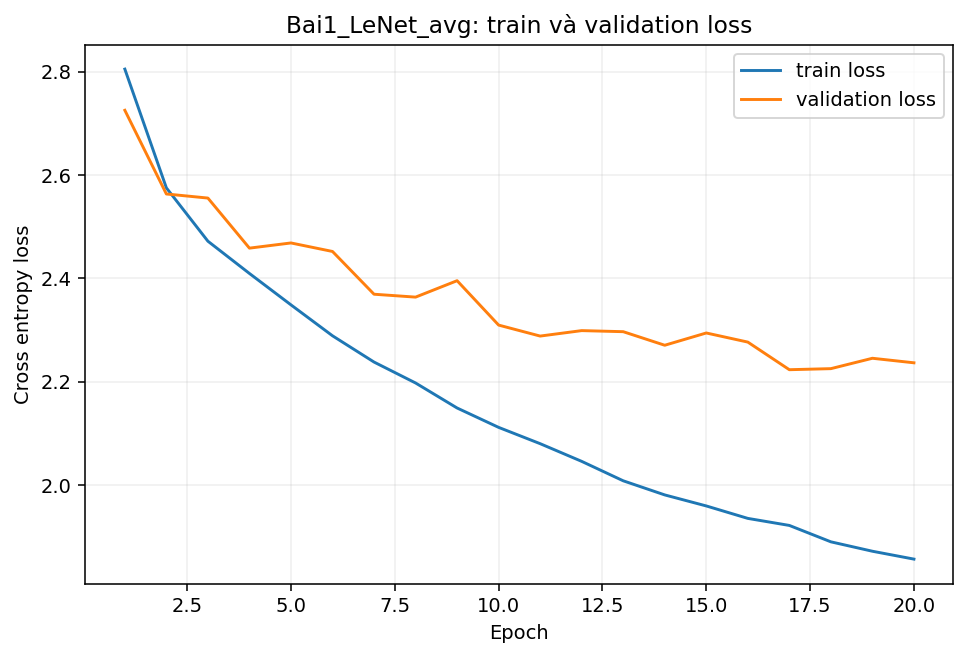

### Hình loss đã lưu — `Bai1_LeNet_max_loss.png`

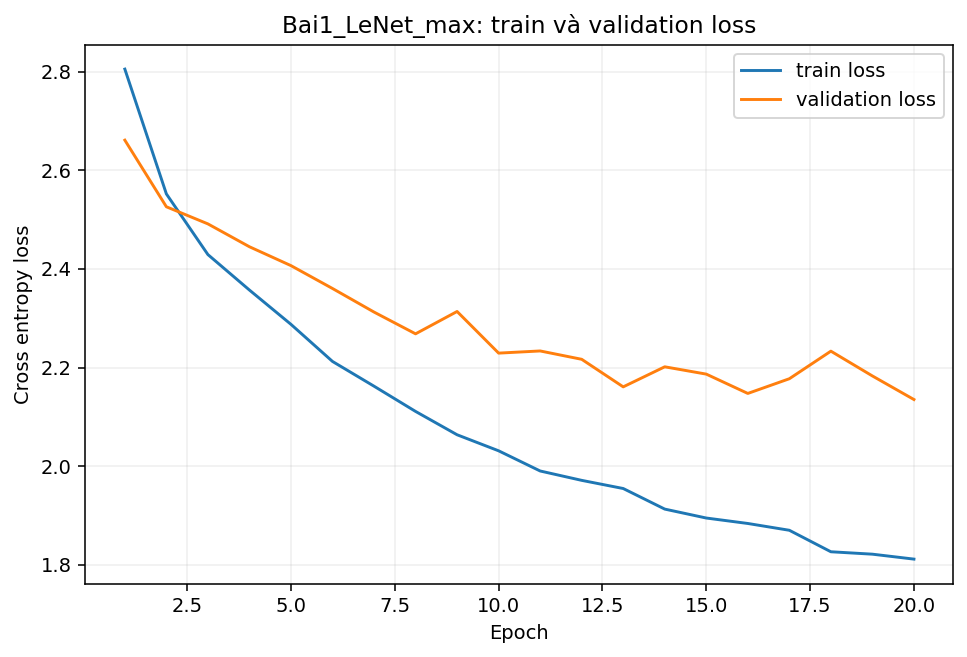

In [7]:
loss_files = sorted(OUTPUT_DIR.glob("*_loss.png"))
for path in loss_files:
    display(Markdown(f"### Hình loss đã lưu — `{path.name}`"))
    display(Image(filename=str(path)))

## 6. Kết quả đánh giá trên test

In [8]:
test_files = sorted(OUTPUT_DIR.glob("*_test.json"))
if not test_files:
    raise FileNotFoundError("Không có test JSON; cell evaluate chưa chạy thành công.")

summaries = []
for path in test_files:
    with path.open(encoding="utf-8") as stream:
        payload = json.load(stream)
    row = payload["summary"].copy()
    row["result_file"] = path.name
    summaries.append(row)

summary_frame = pd.DataFrame(summaries)
preferred = [
    "model", "best_val_epoch", "best_val_f1", "test_loss",
    "accuracy", "precision_macro", "recall_macro", "f1_macro",
    "params", "trainable_params", "seconds_per_epoch", "result_file",
]
shown = [column for column in preferred if column in summary_frame.columns]
display(summary_frame[shown].round(4))

winner = summary_frame.loc[summary_frame["f1_macro"].astype(float).idxmax()]
display(Markdown(
    f"**Mô hình tốt nhất trên test:** `{winner['model']}` — "
    f"accuracy = **{float(winner['accuracy']):.4f}**, "
    f"precision-macro = **{float(winner['precision_macro']):.4f}**, "
    f"recall-macro = **{float(winner['recall_macro']):.4f}**, "
    f"macro-F1 = **{float(winner['f1_macro']):.4f}**."
))

,model,best_val_epoch,best_val_f1,test_loss,accuracy,precision_macro,recall_macro,f1_macro,result_file
0,Bai1_LeNet_avg,19,0.3315,2.3976,0.3031,0.2929,0.2897,0.2800,Bai1_LeNet_avg_test.json
1,Bai1_LeNet_max,13,0.3388,2.2780,0.3239,0.3235,0.3047,0.2967,Bai1_LeNet_max_test.json


**Mô hình tốt nhất trên test:** `Bai1_LeNet_max` — accuracy = **0.3239**, precision-macro = **0.3235**, recall-macro = **0.3047**, macro-F1 = **0.2967**.

## 7. Kết quả từng lớp

In [9]:
per_class_files = sorted(OUTPUT_DIR.glob("*_per_class.csv"))
for path in per_class_files:
    frame = pd.read_csv(path).sort_values("f1", ascending=False)
    display(Markdown(f"### Precision/Recall/F1 từng lớp — `{path.stem.removesuffix('_per_class')}`"))
    display(frame.round(4))

### Precision/Recall/F1 từng lớp — `Bai1_LeNet_avg`

,class,precision,recall,f1,support
13,canh-khoai-mo,0.7627,0.6818,0.7200,198
9,bo-la-lot,0.5273,0.5066,0.5167,458
12,canh-kho-qua,0.3537,0.6379,0.4551,290
19,tau-hu,0.3610,0.4926,0.4167,203
1,banh-hoi,0.3268,0.4366,0.3738,607
2,banh-mi-chao,0.2977,0.4048,0.3431,289
8,bo-kho,0.3183,0.2929,0.3051,338
6,banh-uot,0.3119,0.2679,0.2882,560
20,thit-kho-trung,0.3080,0.2369,0.2678,325
14,ga-nuong,0.2929,0.2204,0.2515,372


### Precision/Recall/F1 từng lớp — `Bai1_LeNet_max`

,class,precision,recall,f1,support
13,canh-khoai-mo,0.7527,0.7071,0.7292,198
9,bo-la-lot,0.4612,0.6354,0.5344,458
12,canh-kho-qua,0.5078,0.5586,0.5320,290
19,tau-hu,0.3481,0.4631,0.3975,203
1,banh-hoi,0.3113,0.5206,0.3896,607
2,banh-mi-chao,0.3025,0.3841,0.3384,289
8,bo-kho,0.2851,0.4024,0.3337,338
6,banh-uot,0.3006,0.3339,0.3164,560
3,banh-tet,0.4362,0.2253,0.2971,364
20,thit-kho-trung,0.3191,0.2523,0.2818,325


## 8. Confusion matrix

### Confusion matrix — `Bai1_LeNet_avg`

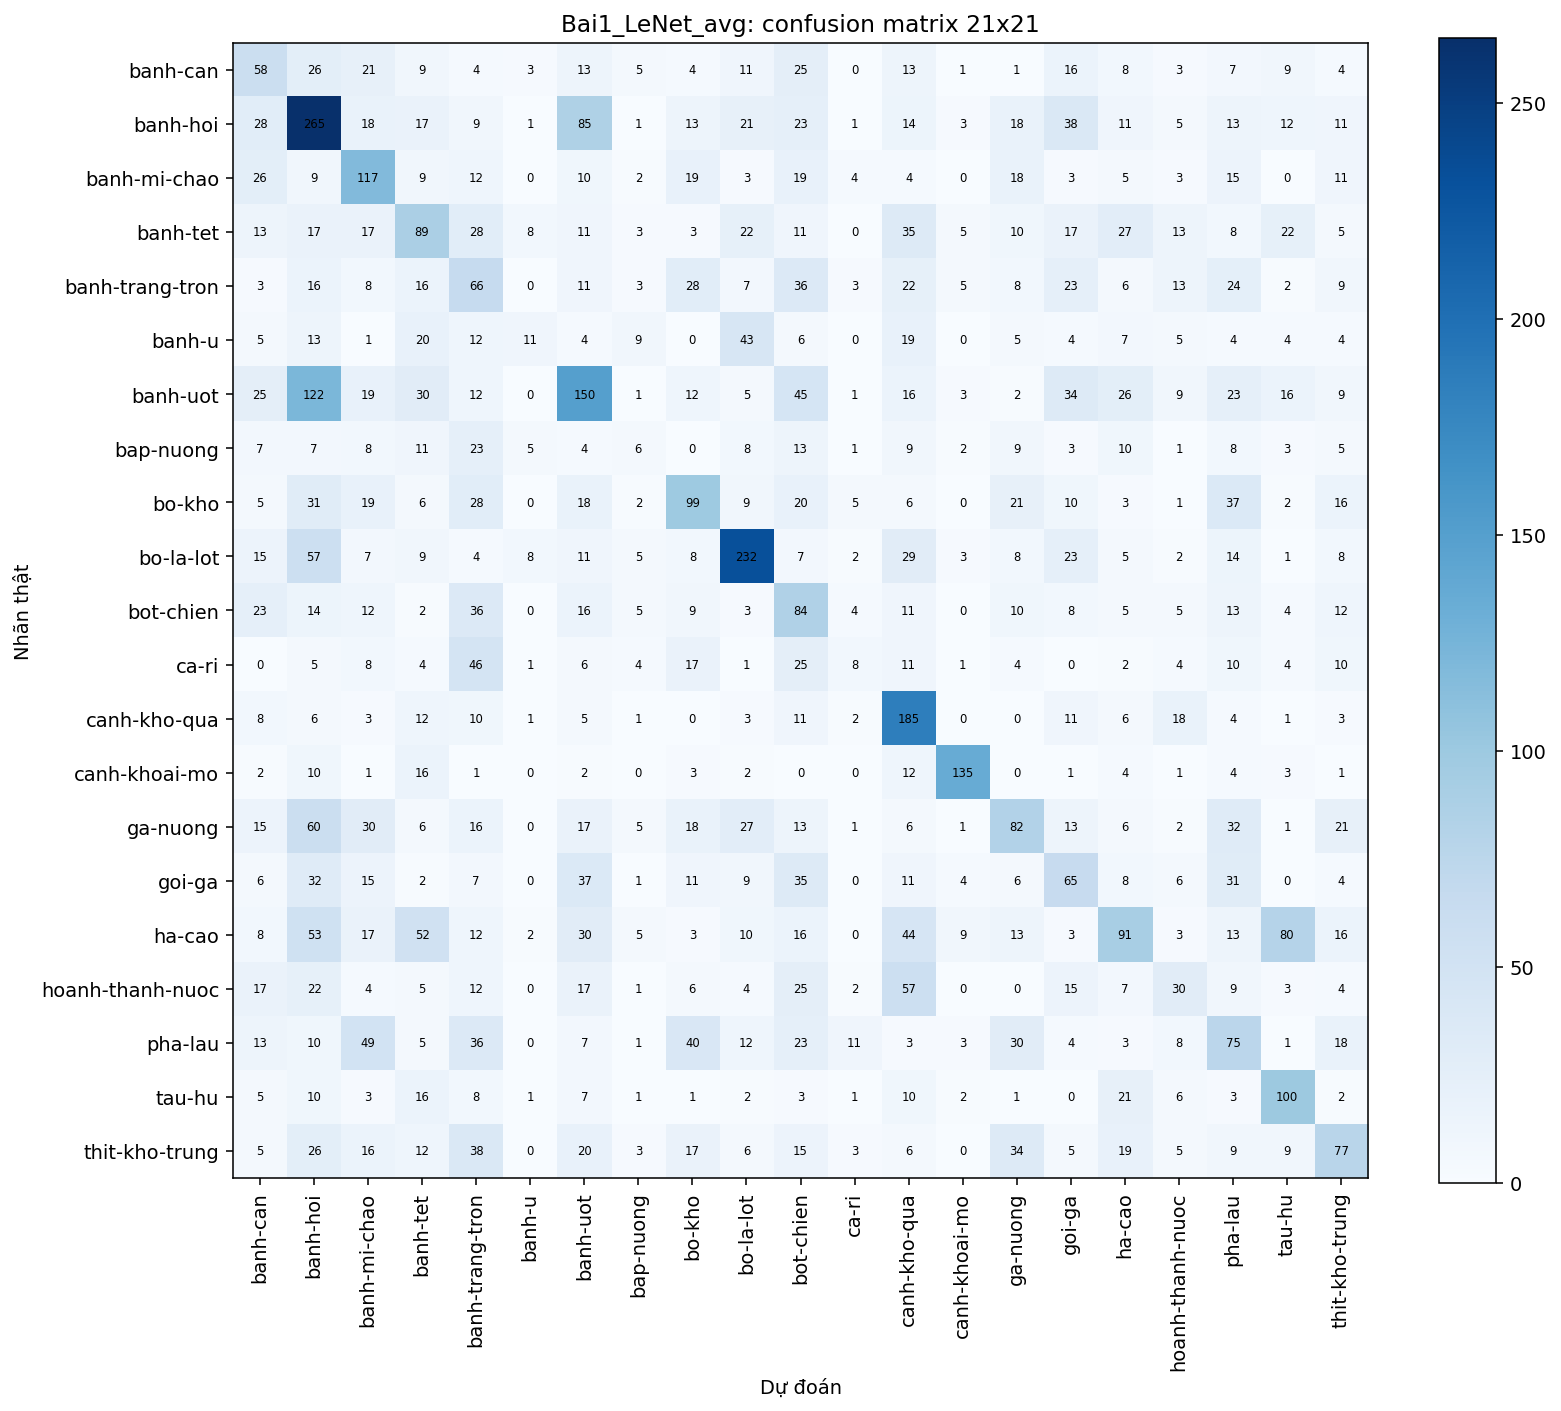

### Confusion matrix — `Bai1_LeNet_max`

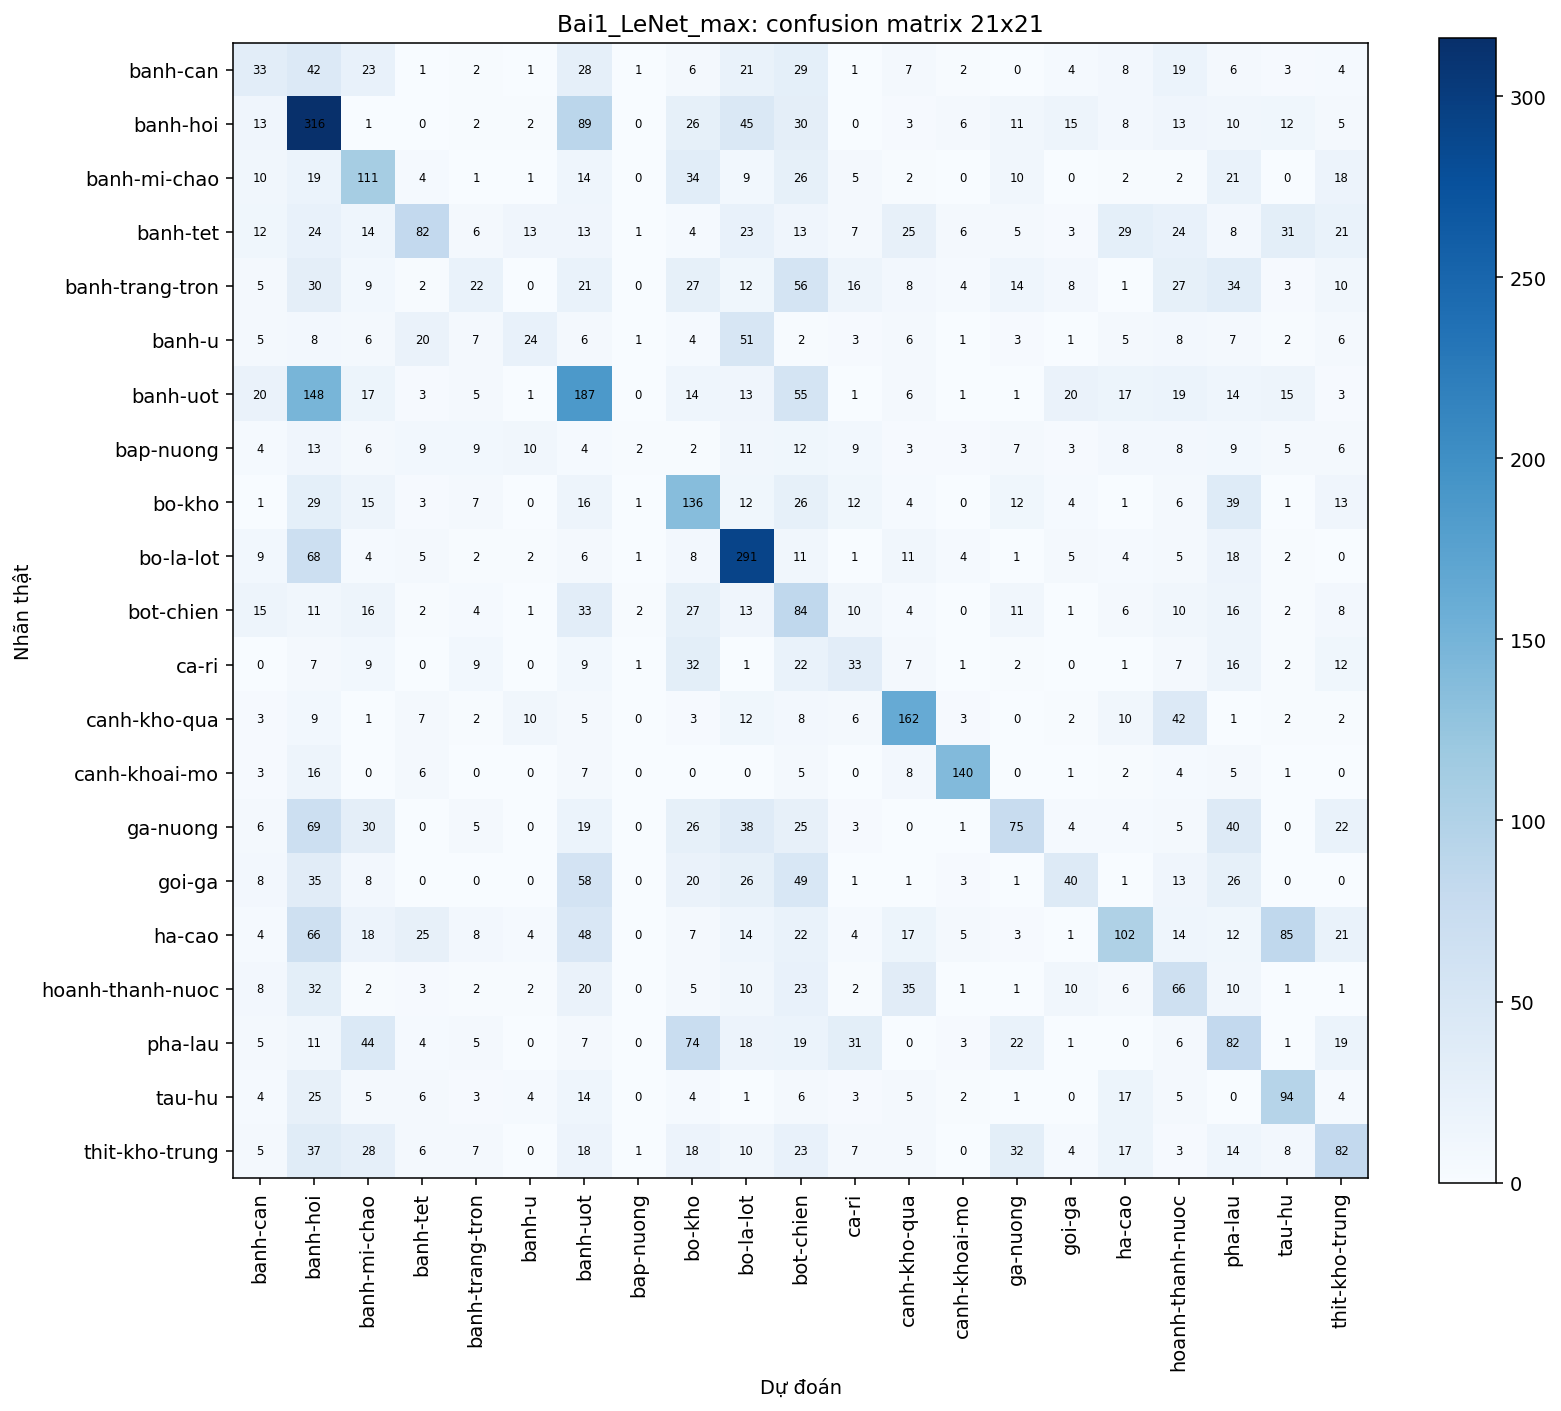

In [10]:
matrix_files = sorted(OUTPUT_DIR.glob("*_confusion_matrix.png"))
for path in matrix_files:
    display(Markdown(f"### Confusion matrix — `{path.stem.removesuffix('_confusion_matrix')}`"))
    display(Image(filename=str(path)))

## 9. Danh sách artifact

In [11]:
rows = [
    {"file": path.name, "size_MB": round(path.stat().st_size / 1024**2, 3)}
    for path in sorted(OUTPUT_DIR.glob("*")) if path.is_file()
]
display(pd.DataFrame(rows))
print("Tất cả artifact được lưu tại:", OUTPUT_DIR)

,file,size_MB
0,Bai1_LeNet_avg_best.pt,1.299
1,Bai1_LeNet_avg_confusion_matrix.png,0.185
2,Bai1_LeNet_avg_history.csv,0.002
3,Bai1_LeNet_avg_loss.png,0.055
4,Bai1_LeNet_avg_per_class.csv,0.001
5,Bai1_LeNet_avg_test.json,0.008
6,Bai1_LeNet_max_best.pt,1.299
7,Bai1_LeNet_max_confusion_matrix.png,0.181
8,Bai1_LeNet_max_history.csv,0.002
9,Bai1_LeNet_max_loss.png,0.057


Tất cả artifact được lưu tại: /kaggle/working/lab2_bai1_outputs


## Kết luận

- Checkpoint được lựa chọn bằng **macro-F1 trên validation**, không dùng test để chọn epoch.
- Các chỉ số test gồm accuracy, precision-macro, recall-macro và macro-F1.